<a href="https://colab.research.google.com/github/pujita-achary/Spectral-COD-/blob/main/Final_Year_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
c!pip -q install segment-anything tifffile opencv-python-headless pyyaml tqdm

In [ ]:
!python step0_check_sam.py


python3: can't open file '/content/step0_check_sam.py': [Errno 2] No such file or directory


In [ ]:
"""
Step 0: can SAM ViT-B load and run on a free T4/P100, and how much memory does it use?

Usage (Colab/Kaggle cell):
    !pip -q install segment-anything tifffile opencv-python-headless pyyaml tqdm
    !python step0_check_sam.py                 # full check
    !python step0_check_sam.py --cpu_only      # CPU sanity only (no GPU quota used)

What it measures (all with the SAM image encoder only; mask decoder is tiny):
  A) inference, fp32, no_grad               -> baseline
  B) inference, fp16 autocast, no_grad      -> what eval will cost
  C) TRAIN-LIKE, frozen weights, autocast, grads flowing through all blocks
     (this is what adapter fine-tuning costs: weights frozen, but activations
      must be stored for backprop). Run for batch 1 and 2.
"""
import argparse, os, sys, time, urllib.request, gc
import torch

CKPT_URL = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"

def download(path):
    if os.path.exists(path) and os.path.getsize(path) > 3.5e8:
        print(f"[ok] checkpoint present: {path}")
        return
    print("[..] downloading SAM ViT-B checkpoint (~375 MB)")
    urllib.request.urlretrieve(CKPT_URL, path)
    print(f"[ok] saved {path} ({os.path.getsize(path)/1e6:.0f} MB)")

def gb(x): return x / 1024**3

def measure(tag, fn, device):
    """Run fn(), report peak GPU memory + time. Catches OOM so one failure doesn't kill the script."""
    if device == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    t0 = time.time()
    try:
        out_shape = fn()
        if device == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0
        mem = f"{gb(torch.cuda.max_memory_allocated()):.2f} GB peak" if device == "cuda" else "n/a (CPU)"
        print(f"[PASS] {tag:<48} out={out_shape}  {mem}  {dt:.2f}s")
    except torch.cuda.OutOfMemoryError:
        print(f"[OOM ] {tag:<48} -> out of memory")
    except Exception as e:
        print(f"[FAIL] {tag:<48} -> {type(e).__name__}: {e}")
    finally:
        gc.collect()
        if device == "cuda": torch.cuda.empty_cache()

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt", default="sam_vit_b_01ec64.pth")
    ap.add_argument("--cpu_only", action="store_true")
    args, _ = ap.parse_known_args()  # tolerate Jupyter's extra "-f kernel.json" arg

    import torchvision
    print("versions: torch", torch.__version__, "| torchvision", torchvision.__version__,
          "| python", sys.version.split()[0])
    device = "cuda" if (torch.cuda.is_available() and not args.cpu_only) else "cpu"
    if device == "cuda":
        p = torch.cuda.get_device_properties(0)
        print(f"GPU: {p.name}, {gb(p.total_memory):.1f} GB total")
    else:
        print("Running on CPU (no GPU memory numbers will be reported)")

    download(args.ckpt)
    from segment_anything import sam_model_registry
    sam = sam_model_registry["vit_b"](checkpoint=args.ckpt)
    enc = sam.image_encoder.to(device).eval()
    for p_ in enc.parameters():
        p_.requires_grad_(False)          # frozen, as in our plan
    n = sum(p_.numel() for p_ in enc.parameters())
    print(f"[ok] ViT-B image encoder loaded: {n/1e6:.1f}M params (all frozen)")
    if device == "cuda":
        print(f"     weights on GPU: {gb(torch.cuda.memory_allocated()):.2f} GB")

    # SAM's encoder expects 1x3x1024x1024 (fixed pos-embed for a 64x64 token grid).
    x1 = torch.randn(1, 3, 1024, 1024, device=device)

    def a():
        with torch.no_grad(): return tuple(enc(x1).shape)
    measure("A) infer fp32, B=1", a, device)

    if device == "cuda":
        def b():
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
                return tuple(enc(x1).shape)
        measure("B) infer fp16 autocast, B=1", b, device)

        for bs in (1, 2):
            def c(bs=bs):
                x = torch.randn(bs, 3, 1024, 1024, device=device, requires_grad=True)
                with torch.autocast("cuda", dtype=torch.float16):
                    y = enc(x)
                y.float().mean().backward()   # forces grads through all 12 blocks
                return tuple(y.shape)
            measure(f"C) TRAIN-LIKE fp16, grads through encoder, B={bs}", c, device)
    else:
        print("[info] skipping fp16/train-like tests on CPU")

    print("\nExpected encoder output shape: (B, 256, 64, 64)")
    print("GO/NO-GO guide (T4 has ~15 GB usable): GO on SAM if C) B=1 peaks <~10 GB; "
          "comfortable if B=2 also passes. If C) OOMs -> fallback backbone.")

if __name__ == "__main__":
    main()

versions: torch 2.14.1+cpu | torchvision 0.29.1+cpu | python 3.13.18
Running on CPU (no GPU memory numbers will be reported)
[..] downloading SAM ViT-B checkpoint (~375 MB)
[ok] saved sam_vit_b_01ec64.pth (375 MB)
[ok] ViT-B image encoder loaded: 89.7M params (all frozen)
[PASS] A) infer fp32, B=1                               out=(1, 256, 64, 64)  n/a (CPU)  23.01s
[info] skipping fp16/train-like tests on CPU

Expected encoder output shape: (B, 256, 64, 64)
GO/NO-GO guide (T4 has ~15 GB usable): GO on SAM if C) B=1 peaks <~10 GB; comfortable if B=2 also passes. If C) OOMs -> fallback backbone.


In [ ]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.14.1+cu130 True


In [ ]:
!pip -q install segment-anything

In [ ]:
!python step0_check_sam.py

versions: torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | python 3.13.16
GPU: Tesla T4, 14.6 GB total
[..] downloading SAM ViT-B checkpoint (~375 MB)
[ok] saved sam_vit_b_01ec64.pth (375 MB)
[ok] ViT-B image encoder loaded: 89.7M params (all frozen)
     weights on GPU: 0.33 GB
[PASS] A) infer fp32, B=1                               out=(1, 256, 64, 64)  2.69 GB peak  1.86s
[PASS] B) infer fp16 autocast, B=1                      out=(1, 256, 64, 64)  1.53 GB peak  0.30s
[PASS] C) TRAIN-LIKE fp16, grads through encoder, B=1   out=(1, 256, 64, 64)  7.93 GB peak  0.62s
[W1107 15:13:26.085214857 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1610612736 bytes (free: 456982528, total: 15637086208).
[W1107 15:13:26.122332937 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1610612736 bytes (free: 1262288896, total: 15637086208).
[OOM ] C) TRAIN-LIKE fp16, grads through encoder, B=2   ->

In [ ]:
from google.colab import drive
# When running this cell, make sure to accept the authorization prompt and grant permission.
drive.mount('/content/drive')
!cp sam_vit_b_01ec64.pth /content/drive/MyDrive/

Mounted at /content/drive


In [ ]:
 !ls /content/drive/MyDrive/Dataset

TestDataset  TrainDataset


In [ ]:
!pip -q install h5py scipy opencv-python-headless matplotlib
!python tools/inspect_mcod.py --root /content/drive/MyDrive/Dataset

=== 1) folders ===
TrainDataset/GT: 1027 files, extensions={'.jpg': 1027}
TrainDataset/Mat: 1027 files, extensions={'.mat': 1027}
TrainDataset/Pcolor: 1027 files, extensions={'.png': 1027}
TestDataset/GT: 500 files, extensions={'.jpg': 500}
TestDataset/Mat: 500 files, extensions={'.mat': 500}
TestDataset/Pcolor: 500 files, extensions={'.png': 500}
TrainDataset: in Mat but not GT: 0 | in GT but not Mat: 0 | in Mat but not Pcolor: 0
TestDataset: in Mat but not GT: 0 | in GT but not Mat: 0 | in Mat but not Pcolor: 0

=== 2) one .mat file: 19700101000511487_00-00001.mat ===
loaded with: h5py (v7.3 HDF5) -- NOTE: MATLAB axes come out REVERSED (e.g. 8xWxH)
  var 'gray': shape=(8, 1140, 860) dtype=uint8 min/max=(np.uint8(0), np.uint8(255))
-> cube variable 'gray', band axis guess = axis 0 (size 8), shape (8, 1140, 860)
per-band mean/std/min/max (checks bands aren't blank or mis-scaled):
  S1: mean=   97.717 std=   30.386 min=   36.000 max=  255.000
  S2: mean=  126.964 std=   44.590 min=   32

In [ ]:
!pip -q install h5py

In [ ]:
!python tools/copy_subset.py --src /content/drive/MyDrive/Dataset --dst /content/mcod_dev --n_train 200 --n_test 50

TrainDataset: 1027 matched stems available, copying 200
  10/200
  20/200
  30/200
  40/200
  50/200
  60/200
  70/200
  80/200
  90/200
  100/200
  110/200
  120/200
  130/200
  140/200
  150/200
  160/200
  170/200
  180/200
  190/200
  200/200
TrainDataset: done, failed=0 []
TestDataset: 500 matched stems available, copying 50
  10/50
  20/50
  30/50
  40/50
  50/50
TestDataset: done, failed=0 []


In [ ]:
!python tools/inspect_mcod.py --root /content/mcod_dev

=== 1) folders ===
TrainDataset/GT: 200 files, extensions={'.jpg': 200}
TrainDataset/Mat: 200 files, extensions={'.mat': 200}
TrainDataset/Pcolor: 200 files, extensions={'.png': 200}
TestDataset/GT: 50 files, extensions={'.jpg': 50}
TestDataset/Mat: 50 files, extensions={'.mat': 50}
TestDataset/Pcolor: 50 files, extensions={'.png': 50}
TrainDataset: in Mat but not GT: 0 | in GT but not Mat: 0 | in Mat but not Pcolor: 0
TestDataset: in Mat but not GT: 0 | in GT but not Mat: 0 | in Mat but not Pcolor: 0

=== 2) one .mat file: 19700101000540162_00-00003.mat ===
loaded with: h5py (v7.3 HDF5): axes are REVERSED vs MATLAB
  var 'gray': shape=(8, 1140, 860) dtype=uint8 min/max=(np.uint8(17), np.uint8(255))
-> cube variable 'gray', band axis guess = axis 0 (size 8), shape (8, 1140, 860)
raw cube after moving band axis last: (1140, 860, 8); mask shape: (860, 1140)
-> ORIENTATION: spatial axes must be SWAPPED to match mask (cube.transpose(1,0,...)).
per-band mean/std/min/max (checks bands aren't

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
import os

backup = '/content/drive/MyDrive/Final_Year_Project_Backup'

os.makedirs(backup, exist_ok=True)

shutil.copytree(
    '/content/tools',
    backup + '/tools',
    dirs_exist_ok=True
)

print("Tools folder backed up successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tools folder backed up successfully!


In [ ]:
shutil.copy(
    '/content/inspect_mcod.png',
    backup + '/inspect_mcod.png'
)

'/content/drive/MyDrive/Final_Year_Project_Backup/inspect_mcod.png'

In [ ]:
!ls -lah /content/

total 768K
drwxr-xr-x 1 root root 4.0K Nov 10 15:59 .
drwxr-xr-x 1 root root 4.0K Nov 10 15:16 ..
drwxr-xr-x 4 root root 4.0K Nov  6 16:54 .config
drwx------ 5 root root 4.0K Nov 10 15:41 drive
-rw-r--r-- 1 root root 730K Nov 10 15:59 inspect_mcod.png
drwxr-xr-x 2 root root 4.0K Nov 10 15:39 .ipynb_checkpoints
drwxr-xr-x 4 root root 4.0K Nov 10 15:58 mcod_dev
drwxr-xr-x 1 root root 4.0K Nov 10 15:38 sample_data
drwxr-xr-x 3 root root 4.0K Nov 10 15:45 tools


In [ ]:
!ls -lah /content/drive/MyDrive/Final_Year_Project_Backup/

total 742K
drwx------ 3 root root 4.0K Nov 10 16:07 .
drwx------ 3 root root 4.0K Nov 10 15:41 ..
-rw------- 1 root root 730K Nov 10 16:07 inspect_mcod.png
drwx------ 3 root root 4.0K Nov 10 15:45 tools


In [ ]:
!ls -lah /content/drive/MyDrive/Final_Year_Project_Backup/tools/

total 23K
drwx------ 3 root root 4.0K Nov 10 15:45 .
drwx------ 3 root root 4.0K Nov 10 16:07 ..
-rw------- 1 root root 2.8K Nov 10 15:45 copy_subset.py
-rw------- 1 root root 8.0K Nov 10 15:45 inspect_mcod.py
drwx------ 2 root root 4.0K Nov 10 15:45 .ipynb_checkpoints


In [ ]:
!unzip -oq spectral_cod.zip
%cd /content/spectral_cod

/content/spectral_cod


In [ ]:
!python tests/test_data.py

PASS shapes/contract: {'cube': (8, 64, 64), 'mask': (1, 64, 64), 'valid': (1, 64, 64), 'attrs': (8,), 'has_attrs': (), 'orig_hw': (2,), 'box': (4,), 'area_ratio': ()}
PASS orientation: cube is (H,W,8), aligned with mask
PASS letterbox->unletterbox round trip (last IoU vs original mask = 0.995, S=64)
PASS augmentation keeps cube/mask aligned over 60 random draws (worst IoU 1.000)
PASS band dropout only touches candidate bands (0, 3, 5, 6, 7); pseudo-RGB bands (4, 2, 1) protected
PASS DataLoader batch + attribute CSV: {'cube': (2, 8, 64, 64), 'mask': (2, 1, 64, 64), 'valid': (2, 1, 64, 64), 'attrs': (2, 8), 'has_attrs': (2,), 'orig_hw': (2, 2), 'box': (2, 4), 'area_ratio': (2,)}
PASS wrong n_bands fails loudly: no axis of size n_bands=200 in (8, 80, 60)

ALL SYNTHETIC TESTS PASSED


In [ ]:
!python tools/copy_subset.py --src /content/drive/MyDrive/Dataset --dst /content/mcod_dev --n_train 200 --n_test 50

TrainDataset: 1027 matched stems available, copying 200
  10/200
  20/200
  30/200
  40/200
  50/200
  60/200
  70/200
  80/200
  90/200
  100/200
  110/200
  120/200
  130/200
  140/200
  150/200
  160/200
  170/200
  180/200
  190/200
  200/200
TrainDataset: done, failed=0 []
TestDataset: 500 matched stems available, copying 50
  10/50
  20/50
  30/50
  40/50
  50/50
TestDataset: done, failed=0 []


TestDataset  test_stems.txt  TrainDataset  train_stems.txt
PASS shapes/contract: {'cube': (8, 64, 64), 'mask': (1, 64, 64), 'valid': (1, 64, 64), 'attrs': (8,), 'has_attrs': (), 'orig_hw': (2,), 'box': (4,), 'area_ratio': ()}
PASS orientation: cube is (H,W,8), aligned with mask
PASS letterbox->unletterbox round trip (last IoU vs original mask = 0.995, S=64)
PASS augmentation keeps cube/mask aligned over 60 random draws (worst IoU 1.000)
PASS band dropout only touches candidate bands (0, 3, 5, 6, 7); pseudo-RGB bands (4, 2, 1) protected
PASS DataLoader batch + attribute CSV: {'cube': (2, 8, 64, 64), 'mask': (2, 1, 64, 64), 'valid': (2, 1, 64, 64), 'attrs': (2, 8), 'has_attrs': (2,), 'orig_hw': (2, 2), 'box': (2, 4), 'area_ratio': (2,)}
PASS wrong n_bands fails loudly: no axis of size n_bands=200 in (8, 80, 60)

ALL SYNTHETIC TESTS PASSED
REAL data: 200 train images found
  shapes cube (8, 1024, 1024) mask (1, 1024, 1024) box [0, 772, 0, 1024] orig [860, 1140]
  0.34s/sample | area_ratio

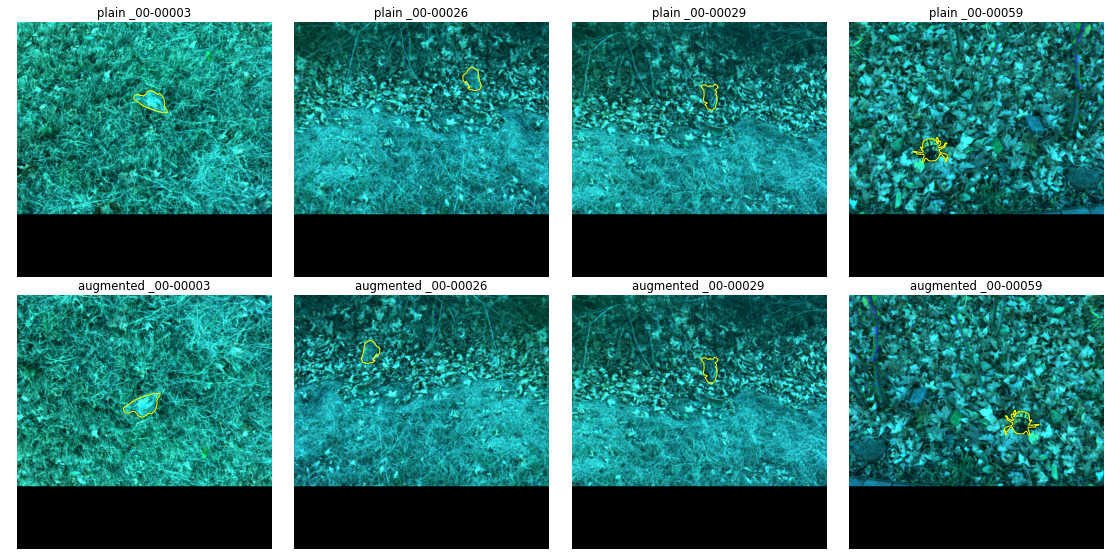

In [ ]:
!ls /content/mcod_dev
!python tests/test_data.py --root /content/mcod_dev --viz check.png
from IPython.display import Image, display
display(Image("check.png"))

In [ ]:
!find /content -maxdepth 3 -name "test_data.py"

In [ ]:
from google.colab import files
uploaded = files.upload()
import zipfile, os
name = list(uploaded.keys())[0]
zipfile.ZipFile(name).extractall("/content")
!ls /content

Saving spectral_cod (1).zip to spectral_cod (1).zip
 drive	 sample_data   spectral_cod  'spectral_cod (1).zip'


In [ ]:
!find /content -maxdepth 3 -name "test_data.py"

/content/spectral_cod/tests/test_data.py


In [ ]:
%cd /content/spectral_cod
!ls

/content/spectral_cod
configs  data  requirements.txt  step0_check_sam.py  tests  tools


In [ ]:
%cd /content/spectral_cod
!mkdir -p models tests
!touch models/__init__.py
!ls

/content/spectral_cod
configs  data  models  requirements.txt  step0_check_sam.py  tests  tools


In [ ]:
%%writefile models/ssdm.py
"""SSDM (Spectral-Spatial Decomposition Module), part A: pseudo-RGB I_M.
No learnable parameters. Input cube (B,8,S,S) in [0,1], valid (B,1,S,S).
Output dict: I_M (B,3,S,S) float in [0,1], padding = 0.
"""
import torch
import torch.nn as nn


class SSDM(nn.Module):
    def __init__(self, rgb_idx=(4, 2, 1), rgb_norm="percentile",
                 p_low=0.01, p_high=0.99, eps=1e-6):
        super().__init__()
        assert rgb_norm in ("percentile", "none")
        self.rgb_idx = tuple(rgb_idx)
        self.rgb_norm = rgb_norm
        self.p_low, self.p_high, self.eps = p_low, p_high, eps

    @torch.no_grad()
    def make_pseudo_rgb(self, cube, valid):
        rgb = cube[:, list(self.rgb_idx)]           # (B,3,S,S)
        if self.rgb_norm == "none":
            return rgb * valid
        out = torch.zeros_like(rgb)
        m = valid[:, 0] > 0.5                        # (B,S,S) bool
        q = torch.tensor([self.p_low, self.p_high],
                         device=rgb.device, dtype=rgb.dtype)
        for b in range(rgb.shape[0]):
            for c in range(rgb.shape[1]):
                v = rgb[b, c][m[b]]                  # real pixels only
                if v.numel() == 0:
                    continue
                lo, hi = torch.quantile(v, q)
                scale = (hi - lo).clamp_min(self.eps)
                out[b, c] = ((rgb[b, c] - lo) / scale).clamp(0, 1)
        return out * valid

    @torch.no_grad()
    def forward(self, cube, valid):
        return {"I_M": self.make_pseudo_rgb(cube, valid)}

Writing models/ssdm.py


In [ ]:
!ls models && head -5 models/ssdm.py

__init__.py  ssdm.py
"""SSDM (Spectral-Spatial Decomposition Module), part A: pseudo-RGB I_M.
No learnable parameters. Input cube (B,8,S,S) in [0,1], valid (B,1,S,S).
Output dict: I_M (B,3,S,S) float in [0,1], padding = 0.
"""
import torch


In [ ]:
%%writefile tests/test_ssdm.py
import sys, os
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import torch
from models.ssdm import SSDM

torch.manual_seed(0)
B, S = 2, 64
cube = torch.rand(B, 8, S, S)
cube[:, 4] *= 0.2                      # make S5 dark, like real data
valid = torch.zeros(B, 1, S, S)
valid[:, :, :48, :] = 1                # bottom rows = padding
cube = cube * valid

m = SSDM()
assert sum(p.numel() for p in m.parameters()) == 0
out = m(cube, valid)["I_M"]
assert out.shape == (B, 3, S, S) and out.dtype == torch.float32
assert out.min() >= 0 and out.max() <= 1
assert out[:, :, 48:, :].abs().max() == 0, "padding must be 0"
print("PASS shape / range / padding / no params")

# channel mapping: with no stretch, R=S5, G=S3, B=S2
raw = SSDM(rgb_norm="none")(cube, valid)["I_M"]
assert torch.equal(raw[:, 0], cube[:, 4])
assert torch.equal(raw[:, 1], cube[:, 2])
assert torch.equal(raw[:, 2], cube[:, 1])
print("PASS channel mapping R=S5 G=S3 B=S2")

# per-channel stretch: dark S5 must now reach a similar level as the others
v = valid[:, 0] > 0.5
hi = [out[0, c][v[0]].max().item() for c in range(3)]
print("max per channel after stretch (should all be ~1.0):", hi)
assert all(h > 0.99 for h in hi)
print("PASS per-channel stretch")

Writing tests/test_ssdm.py


In [ ]:
!python tests/test_ssdm.py

PASS shape / range / padding / no params
PASS channel mapping R=S5 G=S3 B=S2
max per channel after stretch (should all be ~1.0): [1.0, 1.0, 1.0]
PASS per-channel stretch


In [ ]:
%%writefile models/saliency.py
"""Saliency maths for SSDM. Variant V1 'pyramid_sad' (PROPOSED reading of HSC-SAM's SSG).
All functions: no learnable parameters, intended for torch.no_grad().
"""
import torch
import torch.nn.functional as F

_K1D = torch.tensor([1., 4., 6., 4., 1.]) / 16.


def band_normalize(cube, valid, mode="mean", eps=1e-6):
    """PROPOSED: divide each band by its mean over valid pixels (fixes dark S5)."""
    if mode == "none":
        return cube * valid
    s = valid.sum((2, 3), keepdim=True).clamp_min(1.0)
    mean = (cube * valid).sum((2, 3), keepdim=True) / s
    return cube / (mean + eps) * valid


def blur_down(x):
    """5-tap [1,4,6,4,1] Gaussian blur, then keep every 2nd pixel."""
    C = x.shape[1]
    k = _K1D.to(device=x.device, dtype=x.dtype)
    k2 = (k[:, None] * k[None, :])[None, None].repeat(C, 1, 1, 1)
    x = F.pad(x, (2, 2, 2, 2), mode="replicate")
    return F.conv2d(x, k2, stride=2, groups=C)


def gaussian_pyramid(x, n_levels):
    """Returns a list; list[0] is level 1 (full size), list[k-1] is level k."""
    levels = [x]
    for _ in range(n_levels - 1):
        levels.append(blur_down(levels[-1]))
    return levels


def sad_map(a, b, eps=1e-6):
    """Spectral angle (radians) between per-pixel vectors a, b of shape (B,C,H,W)."""
    dot = (a * b).sum(1, keepdim=True)
    na = a.norm(dim=1, keepdim=True)
    nb = b.norm(dim=1, keepdim=True)
    cos = (dot / (na * nb).clamp_min(eps)).clamp(-1.0, 1.0)
    ok = ((na > eps) & (nb > eps)).to(cos.dtype)
    return torch.acos(cos) * ok


def pyramid_sad(cube_n, valid, levels=(2, 3, 4), offset=3):
    """V1: channel c = SAD(up(level c), up(level c+offset)). Returns raw (B,3,H,W), radians."""
    size = cube_n.shape[-2:]
    pyr = gaussian_pyramid(cube_n, max(levels) + offset)
    maps = []
    for c in levels:
        a = F.interpolate(pyr[c - 1], size=size, mode="bilinear", align_corners=False)
        b = F.interpolate(pyr[c - 1 + offset], size=size, mode="bilinear", align_corners=False)
        maps.append(sad_map(a, b))
    return torch.cat(maps, dim=1) * valid


def robust_normalize(x, valid, p_hi=0.995, eps=1e-6):
    """Per image, per channel: map [min, p_hi quantile] over valid pixels to [0,1]. Padding = 0."""
    out = torch.zeros_like(x)
    m = valid[:, 0] > 0.5
    q = torch.tensor([p_hi], device=x.device, dtype=x.dtype)
    for b in range(x.shape[0]):
        for c in range(x.shape[1]):
            v = x[b, c][m[b]]
            if v.numel() == 0:
                continue
            lo = v.min()
            hi = torch.quantile(v, q)[0]
            out[b, c] = ((x[b, c] - lo) / (hi - lo).clamp_min(eps)).clamp(0, 1)
    return out * valid

Writing models/saliency.py


In [ ]:
%%writefile tests/test_saliency.py
import sys, os
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import torch
from models.saliency import band_normalize, pyramid_sad, robust_normalize

torch.manual_seed(0)
S = 256
valid = torch.ones(1, 1, S, S)
valid[:, :, 192:, :] = 0                     # bottom quarter = padding

def make(kind):
    spec = torch.linspace(0.3, 0.6, 8).view(1, 8, 1, 1)
    cube = spec.expand(1, 8, S, S).clone() + 0.01 * torch.randn(1, 8, S, S)
    if kind == "spectral":                   # NIR bands S6..S8 x1.3, visible same
        cube[:, 5:, 60:124, 60:124] *= 1.3
    if kind == "dark":                       # same spectral shape, just darker
        cube[:, :, 60:124, 60:124] *= 0.5
    return cube * valid

def inside_outside(raw):
    ins = raw[:, :, 70:114, 70:114].mean().item()
    out = raw[:, :, 130:180, 130:250].mean().item()
    return ins, out

res = {}
for kind in ["plain", "spectral", "dark"]:
    cube_n = band_normalize(make(kind), valid, mode="none")
    raw = pyramid_sad(cube_n, valid)
    assert raw.shape == (1, 3, S, S) and torch.isfinite(raw).all()
    assert raw[:, :, 192:, :].abs().max() == 0, "padding must be 0"
    res[kind] = inside_outside(raw)
    print(kind, "inside/outside mean SAD (rad): %.4f / %.4f" % res[kind])
print("PASS shape / finite / padding")

assert res["spectral"][0] > 3 * res["spectral"][1]
print("PASS spectral object: inside > 3x outside")
assert res["dark"][0] < 0.5 * res["spectral"][0]
print("PASS darker-only object gives much less response than spectral object")

# band_normalize: each band mean over valid pixels ~ 1
cn = band_normalize(make("plain"), valid, mode="mean")
means = (cn * valid).sum((2, 3)) / valid.sum()
assert torch.allclose(means, torch.ones_like(means), atol=1e-3)
print("PASS band_normalize mean=1")

# robust_normalize range + padding
nrm = robust_normalize(pyramid_sad(band_normalize(make("spectral"), valid), valid), valid)
assert nrm.min() >= 0 and nrm.max() <= 1 and nrm[:, :, 192:, :].abs().max() == 0
print("PASS robust_normalize range / padding")

Writing tests/test_saliency.py


In [ ]:
!python tests/test_saliency.py

plain inside/outside mean SAD (rad): 0.0023 / 0.0023
spectral inside/outside mean SAD (rad): 0.0591 / 0.0086
dark inside/outside mean SAD (rad): 0.0024 / 0.0023
PASS shape / finite / padding
PASS spectral object: inside > 3x outside
PASS darker-only object gives much less response than spectral object
PASS band_normalize mean=1
PASS robust_normalize range / padding


In [ ]:
%%writefile models/ssdm.py
"""SSDM (Spectral-Spatial Decomposition Module). No learnable parameters.
Input : cube (B,8,S,S) in [0,1], valid (B,1,S,S)
Output: dict
  I_M     (B,3,S,S) pseudo-RGB in [0,1], padding 0
  I_S     (B,3,S,S) spectral saliency, each channel robust-normalised to [0,1], padding 0
  I_S_raw (B,3,S,S) unnormalised saliency (radians), for tests
Variants (PROPOSED): 'pyramid_sad' is implemented. 'subset_sad', 'index_contrast' come later.
"""
import torch
import torch.nn as nn
from models.saliency import band_normalize, pyramid_sad, robust_normalize


class SSDM(nn.Module):
    def __init__(self, rgb_idx=(4, 2, 1), rgb_norm="percentile",
                 p_low=0.01, p_high=0.99, eps=1e-6,
                 variant="pyramid_sad", band_norm="mean"):
        super().__init__()
        assert rgb_norm in ("percentile", "none")
        assert band_norm in ("mean", "none")
        self.rgb_idx = tuple(rgb_idx)
        self.rgb_norm = rgb_norm
        self.p_low, self.p_high, self.eps = p_low, p_high, eps
        self.variant = variant
        self.band_norm = band_norm

    @torch.no_grad()
    def make_pseudo_rgb(self, cube, valid):
        rgb = cube[:, list(self.rgb_idx)]           # (B,3,S,S)
        if self.rgb_norm == "none":
            return rgb * valid
        out = torch.zeros_like(rgb)
        m = valid[:, 0] > 0.5
        q = torch.tensor([self.p_low, self.p_high],
                         device=rgb.device, dtype=rgb.dtype)
        for b in range(rgb.shape[0]):
            for c in range(rgb.shape[1]):
                v = rgb[b, c][m[b]]
                if v.numel() == 0:
                    continue
                lo, hi = torch.quantile(v, q)
                scale = (hi - lo).clamp_min(self.eps)
                out[b, c] = ((rgb[b, c] - lo) / scale).clamp(0, 1)
        return out * valid

    @torch.no_grad()
    def make_saliency_raw(self, cube, valid):
        cube_n = band_normalize(cube, valid, mode=self.band_norm)
        if self.variant == "pyramid_sad":
            return pyramid_sad(cube_n, valid)
        raise NotImplementedError("variant not implemented yet: " + self.variant)

    @torch.no_grad()
    def forward(self, cube, valid):
        raw = self.make_saliency_raw(cube, valid)
        return {"I_M": self.make_pseudo_rgb(cube, valid),
                "I_S": robust_normalize(raw, valid),
                "I_S_raw": raw}

Overwriting models/ssdm.py


In [ ]:
%%writefile tests/test_ssdm_full.py
import sys, os
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import torch
from models.ssdm import SSDM

torch.manual_seed(0)
B, S = 2, 256
valid = torch.ones(B, 1, S, S); valid[:, :, 192:, :] = 0
spec = torch.linspace(0.3, 0.6, 8).view(1, 8, 1, 1)
cube = spec.expand(B, 8, S, S).clone() + 0.01 * torch.randn(B, 8, S, S)
cube[:, 5:, 60:124, 60:124] *= 1.3           # NIR-only change = "camouflaged" object
cube[:, 4] *= 0.3                            # dark S5, like real data
cube = cube * valid

m = SSDM()
assert sum(p.numel() for p in m.parameters()) == 0
out = m(cube, valid)
for k in ["I_M", "I_S", "I_S_raw"]:
    t = out[k]
    assert t.shape == (B, 3, S, S) and t.dtype == torch.float32 and torch.isfinite(t).all()
    assert t[:, :, 192:, :].abs().max() == 0, k + ": padding must be 0"
print("PASS keys / shapes / finite / padding")
assert out["I_S"].min() >= 0 and out["I_S"].max() <= 1
print("PASS I_S in [0,1]")
ins = out["I_S"][:, :, 70:114, 70:114].mean().item()
outs = out["I_S"][:, :, 130:180, 130:250].mean().item()
print("I_S inside/outside mean: %.3f / %.3f" % (ins, outs))
assert ins > 2 * outs
print("PASS I_S: object brighter than background")
try:
    SSDM(variant="subset_sad")(cube, valid)
    raise SystemExit("should have raised")
except NotImplementedError:
    print("PASS unimplemented variant raises clearly")

Writing tests/test_ssdm_full.py


In [ ]:
!python tests/test_ssdm.py && python tests/test_ssdm_full.py

PASS shape / range / padding / no params
PASS channel mapping R=S5 G=S3 B=S2
max per channel after stretch (should all be ~1.0): [1.0, 1.0, 1.0]
PASS per-channel stretch
PASS keys / shapes / finite / padding
PASS I_S in [0,1]
I_S inside/outside mean: 0.629 / 0.086
PASS I_S: object brighter than background
PASS unimplemented variant raises clearly


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/spectral_cod
!python tools/copy_subset.py --help
!ls /content/drive/MyDrive/Dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Errno 2] No such file or directory: '/content/spectral_cod'
/content
python3: can't open file '/content/tools/copy_subset.py': [Errno 2] No such file or directory
TestDataset  TrainDataset


In [ ]:
%cd /content/spectral_cod
!python tools/copy_subset.py --src /content/drive/MyDrive/Dataset --dst /content/mcod_dev --n_train 200 --n_test 50 --seed 0 --skip_pcolor
!ls /content/mcod_dev
!ls /content/mcod_dev/TrainDataset/Mat | head -3
!ls /content/mcod_dev/TrainDataset/Mat | wc -l

[Errno 2] No such file or directory: '/content/spectral_cod'
/content
python3: can't open file '/content/tools/copy_subset.py': [Errno 2] No such file or directory
ls: cannot access '/content/mcod_dev': No such file or directory
ls: cannot access '/content/mcod_dev/TrainDataset/Mat': No such file or directory
ls: cannot access '/content/mcod_dev/TrainDataset/Mat': No such file or directory
0


In [ ]:
%cd /content/spectral_cod
import inspect
from data.mcod import MCODDataset
print(inspect.signature(MCODDataset.__init__))
ds = MCODDataset("/content/mcod_dev", split="train")
print(len(ds))
s = ds[0]
for k, v in s.items():
    print(k, getattr(v, "shape", v), getattr(v, "dtype", ""))

/content/spectral_cod
(self, root, split='train', img_size=1024, n_bands=8, mat_key='gray', augment=None, crop_prob=0.8, crop_scale=(0.5, 1.0), min_mask_keep=0.5, band_drop_prob=0.0, band_drop_max=1, band_drop_candidates=(0, 3, 5, 6, 7), attr_file=None, limit=None)
200
cube torch.Size([8, 1024, 1024]) torch.float32
mask torch.Size([1, 1024, 1024]) torch.float32
valid torch.Size([1, 1024, 1024]) torch.float32
attrs torch.Size([8]) torch.float32
has_attrs torch.Size([]) torch.bool
name 19700101000540162_00-00003 
orig_hw torch.Size([2]) torch.int64
box torch.Size([4]) torch.int64
area_ratio torch.Size([]) torch.float32


In [ ]:
%%writefile tools/visualize_ssdm.py
import sys, os, argparse
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data.mcod import MCODDataset
from models.ssdm import SSDM

p = argparse.ArgumentParser()
p.add_argument("--root", default="/content/mcod_dev")
p.add_argument("--idx", type=int, nargs="+", default=[0, 50, 100])
p.add_argument("--out_dir", default="/content/ssdm_vis")
args, _ = p.parse_known_args()
os.makedirs(args.out_dir, exist_ok=True)

ds = MCODDataset(args.root, split="train", augment=False)
ssdm = SSDM()

for i in args.idx:
    s = ds[i]
    out = ssdm(s["cube"][None], s["valid"][None])
    I_M = out["I_M"][0].numpy()
    I_S = out["I_S"][0].numpy()
    mask = s["mask"][0].numpy() > 0.5
    valid = s["valid"][0].numpy() > 0.5
    y0, y1, x0, x1 = [int(v) for v in s["box"]]      # crop away padding for display

    def show(ax, img, title, cmap=None):
        ax.imshow(img[y0:y1, x0:x1], cmap=cmap, vmin=0, vmax=1)
        if mask[y0:y1, x0:x1].any():
            ax.contour(mask[y0:y1, x0:x1].astype(float), levels=[0.5], colors="red", linewidths=0.8)
        ax.set_title(title, fontsize=9); ax.axis("off")

    fig, axs = plt.subplots(2, 4, figsize=(16, 6))
    show(axs[0, 0], np.transpose(I_M, (1, 2, 0)), "I_M pseudo-RGB (R=S5,G=S3,B=S2)")
    for c, n in enumerate(["S5 (R)", "S3 (G)", "S2 (B)"]):
        show(axs[0, c + 1], I_M[c], "I_M " + n, "gray")
    show(axs[1, 0], np.transpose(I_S, (1, 2, 0)), "I_S as RGB (levels 2,3,4)")
    for c in range(3):
        show(axs[1, c + 1], I_S[c], "I_S channel %d (pyramid level %d vs %d)" % (c, c + 2, c + 5), "magma")
    fig.suptitle("%s   area_ratio=%.5f" % (s["name"], float(s["area_ratio"])))
    path = os.path.join(args.out_dir, "ssdm_%03d.png" % i)
    fig.savefig(path, dpi=80, bbox_inches="tight"); plt.close(fig)

    bg = valid & ~mask
    ins = [I_S[c][mask].mean() if mask.any() else float("nan") for c in range(3)]
    outs = [I_S[c][bg].mean() for c in range(3)]
    print("idx %d %s | I_S mean inside GT: %s | outside: %s" % (
        i, s["name"], np.round(ins, 3), np.round(outs, 3)))
    print("  saved", path)

Writing tools/visualize_ssdm.py


FileNotFoundError: [Errno 2] No such file or directory: 'tools/visualize_ssdm.py'

In [4]:
from google.colab import files
import zipfile
for _ in range(2):
    up = files.upload()
    for name in up:
        zipfile.ZipFile(name).extractall("/content/spectral_cod" if name.startswith("ssdm") else "/content")
%cd /content/spectral_cod
!ls
!ls models tests tools

Saving ssdm_files.zip to ssdm_files.zip


Saving spectral_cod (1).zip to spectral_cod (1).zip
/content/spectral_cod
configs  data  models  requirements.txt  step0_check_sam.py  tests  tools
models:
__init__.py  saliency.py  ssdm.py

tests:
test_data.py  test_saliency.py	test_ssdm_full.py  test_ssdm.py

tools:
copy_subset.py	inspect_mcod.py  visualize_ssdm.py


In [5]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/spectral_cod
!python tools/copy_subset.py --src /content/drive/MyDrive/Dataset --dst /content/mcod_dev --n_train 200 --n_test 50 --seed 0 --skip_pcolor\

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/spectral_cod
TrainDataset: 1027 matched stems available, copying 200
  10/200
  20/200
  30/200
  40/200
  50/200
  60/200
  70/200
  80/200
  90/200
  100/200
  110/200
  120/200
  130/200
  140/200
  150/200
  160/200
  170/200
  180/200
  190/200
  200/200
TrainDataset: done, failed=0 []
TestDataset: 500 matched stems available, copying 50
  10/50
  20/50
  30/50
  40/50
  50/50
TestDataset: done, failed=0 []


In [3]:
!python tests/test_ssdm.py && python tests/test_saliency.py && python tests/test_ssdm_full.py

PASS shape / range / padding / no params
PASS channel mapping R=S5 G=S3 B=S2
max per channel after stretch (should all be ~1.0): [1.0, 1.0, 1.0]
PASS per-channel stretch
plain inside/outside mean SAD (rad): 0.0023 / 0.0023
spectral inside/outside mean SAD (rad): 0.0591 / 0.0086
dark inside/outside mean SAD (rad): 0.0024 / 0.0023
PASS shape / finite / padding
PASS spectral object: inside > 3x outside
PASS darker-only object gives much less response than spectral object
PASS band_normalize mean=1
PASS robust_normalize range / padding
PASS keys / shapes / finite / padding
PASS I_S in [0,1]
I_S inside/outside mean: 0.629 / 0.086
PASS I_S: object brighter than background
PASS unimplemented variant raises clearly


In [4]:
%cd /content/spectral_cod
import shutil, os
os.makedirs("/content/drive/MyDrive/spectral_cod_backup", exist_ok=True)
shutil.make_archive("/content/drive/MyDrive/spectral_cod_backup/spectral_cod", "zip", "/content", "spectral_cod")
!ls -la /content/drive/MyDrive/spectral_cod_backup
!ls tools

/content/spectral_cod
total 38
drwx------ 2 root root  4096 Nov 16 15:01 .
drwx------ 8 root root  4096 Nov 16 14:42 ..
-rw------- 1 root root 30255 Nov 16 15:01 spectral_cod.zip
copy_subset.py	inspect_mcod.py  visualize_ssdm.py


/content/spectral_cod
idx 0 19700101000540162_00-00003 | I_S mean inside GT: [0.525 0.568 0.759] | outside: [0.288 0.24  0.2  ]
  saved /content/ssdm_vis/ssdm_000.png
idx 50 20000101002050818_00-00051 | I_S mean inside GT: [0.26  0.264 0.305] | outside: [0.264 0.242 0.234]
  saved /content/ssdm_vis/ssdm_050.png
idx 100 20000101005915506_00-00010 | I_S mean inside GT: [0.515 0.733 0.698] | outside: [0.339 0.335 0.321]
  saved /content/ssdm_vis/ssdm_100.png


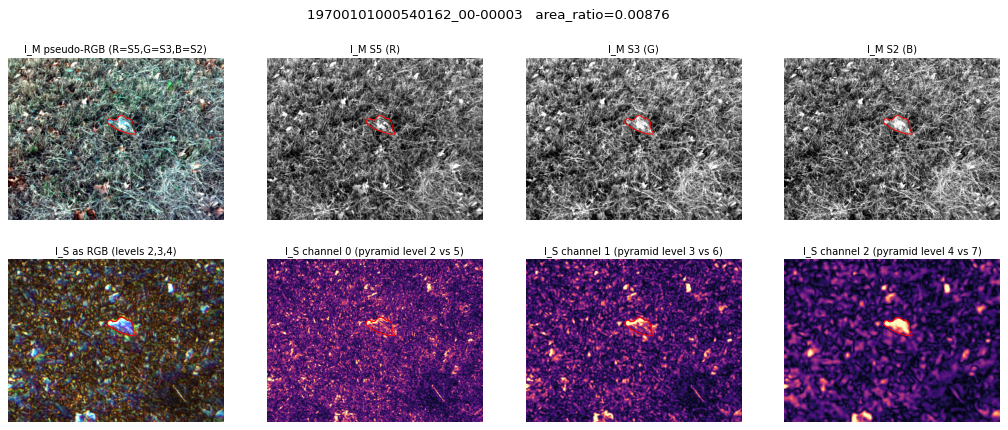

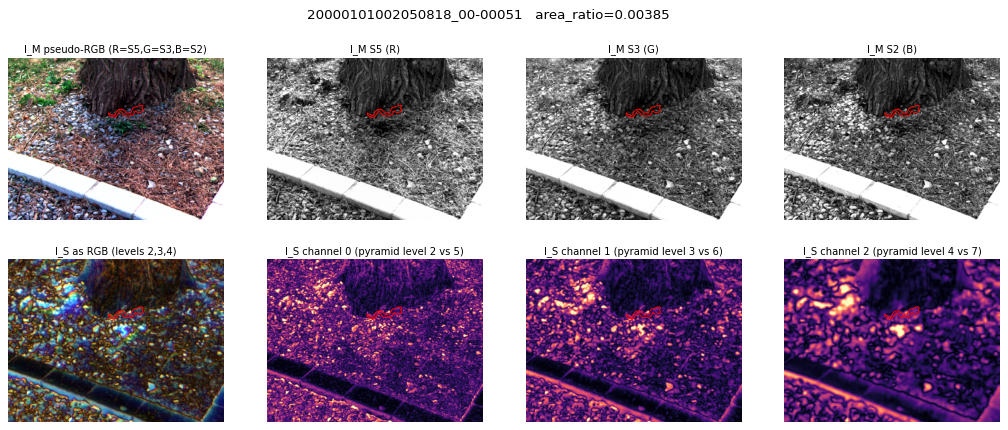

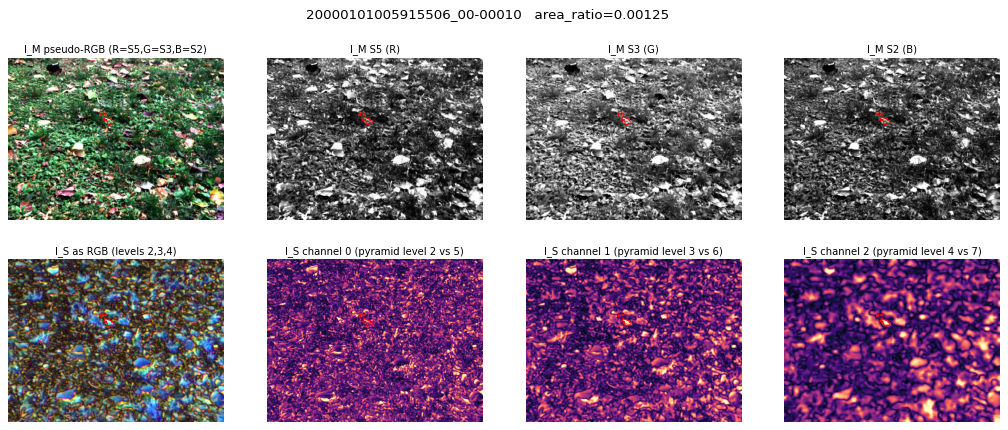

In [5]:
%cd /content/spectral_cod
!python tools/visualize_ssdm.py
from IPython.display import Image, display
for i in [0, 50, 100]:
    display(Image(f"/content/ssdm_vis/ssdm_{i:03d}.png"))

In [1]:
!find /content/drive/MyDrive -maxdepth 3 -name "sam_vit_b_01ec64.pth"
!pip install -q segment-anything
import segment_anything, torch
print("segment_anything OK, torch", torch.__version__, "cuda:", torch.cuda.is_available())

/content/drive/MyDrive/sam_vit_b_01ec64.pth
segment_anything OK, torch 2.14.1+cu130 cuda: True


In [6]:
!unzip -oq /content/drive/MyDrive/spectral_cod_backup/spectral_cod.zip -d /content

In [8]:
%cd /content/spectral_cod
!cp /content/drive/MyDrive/sam_vit_b_01ec64.pth /content/sam_vit_b.pth
!ls -la /content/sam_vit_b.pth

wrapper = r'''"""SAM ViT-B wrapper (PROPOSED baseline): frozen encoder, trainable mask decoder, no prompts.
Input I_M (B,3,S,S) in [0,1], S=1024. Output logits (B,1,S,S).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from segment_anything import sam_model_registry


class SAMSeg(nn.Module):
    def __init__(self, ckpt="/content/sam_vit_b.pth", model_type="vit_b"):
        super().__init__()
        sam = sam_model_registry[model_type](checkpoint=ckpt)
        self.encoder = sam.image_encoder
        self.prompt_encoder = sam.prompt_encoder
        self.decoder = sam.mask_decoder
        self.register_buffer("mean", torch.tensor([123.675, 116.28, 103.53]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([58.395, 57.12, 57.375]).view(1, 3, 1, 1))
        for p in self.encoder.parameters():
            p.requires_grad = False
        for p in self.prompt_encoder.parameters():
            p.requires_grad = False
        self.encoder.eval()

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()
        return self

    @torch.no_grad()
    def encode(self, I_M):
        x = (I_M * 255.0 - self.mean) / self.std
        return self.encoder(x)                       # (B,256,64,64)

    def decode(self, emb, out_size=1024):
        B = emb.shape[0]
        sparse, dense = self.prompt_encoder(points=None, boxes=None, masks=None)
        sparse = sparse.expand(B, -1, -1)
        dense = dense.expand(B, -1, -1, -1)
        low, _ = self.decoder(image_embeddings=emb,
                              image_pe=self.prompt_encoder.get_dense_pe(),
                              sparse_prompt_embeddings=sparse,
                              dense_prompt_embeddings=dense,
                              multimask_output=False)   # (B,1,256,256)
        return F.interpolate(low, size=(out_size, out_size), mode="bilinear", align_corners=False)

    def forward(self, I_M, token_mask=None):
        emb = self.encode(I_M)
        if token_mask is not None:                    # hook for SGTD later (B,1,64,64)
            emb = emb * token_mask
        return self.decode(emb, out_size=I_M.shape[-1])
'''
test = r'''import sys, os, time
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import torch
import torch.nn.functional as F
from data.mcod import MCODDataset
from models.ssdm import SSDM
from models.sam_wrapper import SAMSeg

dev = "cuda"
ds = MCODDataset("/content/mcod_dev", split="train", augment=False)
s = ds[0]
cube, valid, mask = s["cube"][None].to(dev), s["valid"][None].to(dev), s["mask"][None].to(dev)
I_M = SSDM()(cube, valid)["I_M"]

model = SAMSeg().to(dev)
model.train()
n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
print("trainable params: %.2fM of %.2fM" % (n_tr / 1e6, n_all / 1e6))
assert not any(p.requires_grad for p in model.encoder.parameters())

torch.cuda.reset_peak_memory_stats()
with torch.autocast("cuda", dtype=torch.float16):
    emb = model.encode(I_M)
print("embedding", tuple(emb.shape))
assert emb.shape == (1, 256, 64, 64)
emb = emb.float()

opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4)
for it in range(31):
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model.decode(emb)
    loss = F.binary_cross_entropy_with_logits(logits.float(), mask, weight=valid)
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 10 == 0:
        print("step %d loss %.5f" % (it, loss.item()))
assert logits.shape == (1, 1, 1024, 1024)
print("PASS shapes / frozen encoder / decoder trains without error")
pr = torch.sigmoid(logits.float())
m = mask > 0.5
print("DESCRIPTIVE (one image, overfit): mean prob inside GT %.3f, outside %.3f" % (pr[m].mean(), pr[~m & (valid > 0.5)].mean()))
print("peak GPU memory: %.2f GB" % (torch.cuda.max_memory_allocated() / 1e9))
'''
open("models/sam_wrapper.py", "w").write(wrapper)
open("tests/test_sam_wrapper.py", "w").write(test)
print("files written")

/content/spectral_cod
-rw------- 1 root root 375042383 Nov 16 15:24 /content/sam_vit_b.pth
files written


In [9]:
!python tests/test_sam_wrapper.py

trainable params: 4.06M of 93.74M
embedding (1, 256, 64, 64)
step 0 loss 0.12894
step 10 loss 0.03963
step 20 loss 0.02033
step 30 loss 0.01458
PASS shapes / frozen encoder / decoder trains without error
/content/spectral_cod/tests/test_sam_wrapper.py:41: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print("DESCRIPTIVE (one image, overfit): mean prob inside GT %.3f, outside %.3f" % (pr[m].mean(), pr[~m & (valid > 0.5)].mean()))
DESCRIPTIVE (one image, overfit): mean prob inside GT 0.232, outside 0.003
peak GPU memory: 1.72 GB


In [10]:
%cd /content/spectral_cod
import shutil
shutil.make_archive("/content/drive/MyDrive/spectral_cod_backup/spectral_cod", "zip", "/content", "spectral_cod")

/content/spectral_cod


'/content/drive/MyDrive/spectral_cod_backup/spectral_cod.zip'

In [11]:
%cd /content/spectral_cod
loss_code = r'''"""BCE + soft-IoU loss. Padding pixels (valid=0) are ignored (PROPOSED)."""
import torch
import torch.nn.functional as F


def bce_iou_loss(logits, target, valid, eps=1.0):
    """logits, target, valid: (B,1,H,W). Returns scalar = BCE + IoU (equal weights, PROPOSED)."""
    w = valid
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    bce = (bce * w).sum((1, 2, 3)) / w.sum((1, 2, 3)).clamp_min(1.0)
    p = torch.sigmoid(logits) * w
    t = target * w
    inter = (p * t).sum((1, 2, 3))
    union = (p + t - p * t).sum((1, 2, 3))
    iou = 1.0 - (inter + eps) / (union + eps)
    return (bce + iou).mean()
'''
test_code = r'''import sys, os
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
import torch
from losses import bce_iou_loss

torch.manual_seed(0)
B, S = 2, 64
valid = torch.ones(B, 1, S, S); valid[:, :, 48:, :] = 0
target = torch.zeros(B, 1, S, S); target[:, :, 10:20, 10:20] = 1

good = (target * 2 - 1) * 10.0          # confident and correct
bad = -good                              # confident and wrong
l_good = bce_iou_loss(good, target, valid).item()
l_bad = bce_iou_loss(bad, target, valid).item()
print("loss good %.4f | loss bad %.4f" % (l_good, l_bad))
assert l_good < 0.01 and l_bad > 5
print("PASS good prediction ~0, bad prediction large")

noisy = good.clone(); noisy[:, :, 48:, :] = 50.0      # change only the padding
assert abs(bce_iou_loss(noisy, target, valid).item() - l_good) < 1e-6
print("PASS padding is ignored")

x = torch.randn(B, 1, S, S, requires_grad=True)
bce_iou_loss(x, target, valid).backward()
assert torch.isfinite(x.grad).all() and x.grad.abs().sum() > 0
print("PASS gradients finite")

empty = torch.zeros(B, 1, S, S)
assert torch.isfinite(bce_iou_loss(torch.randn(B, 1, S, S), empty, valid))
print("PASS empty mask is finite")
'''
open("losses.py", "w").write(loss_code)
open("tests/test_losses.py", "w").write(test_code)
!python tests/test_losses.py

/content/spectral_cod
loss good 0.0014 | loss bad 10.9997
PASS good prediction ~0, bad prediction large
PASS padding is ignored
PASS gradients finite
PASS empty mask is finite
